# ResNet-50 Losses experiments

## Weigthed Loss

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import medmnist
import numpy as np
import os
import torch.nn.functional as F
import matplotlib.pyplot as plt
import sklearn.metrics as skmetrics
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision import models
from medmnist import INFO, Evaluator
from tqdm import tqdm
from sklearn.metrics import roc_curve, auc as metrics_auc, f1_score, accuracy_score, hamming_loss, balanced_accuracy_score, confusion_matrix

# Early Stopping Class
class EarlyStopping:
    def __init__(self, patience=3, verbose=False, delta=0, path='best_resnet50_standard_28x28.pth'):
        """
        Args:
            patience (int): epochs to wait after the last improvement.
            verbose (bool): if True, prints a message for each improvement.
            delta (float): Minimum change in the monitored metric to be considered as an improvement.
            path (str): Path where the best model will be saved.
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.auc_max = -np.inf
        self.delta = delta
        self.path = path

    def __call__(self, auc, model):
        score = auc

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(auc, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            print(f'EarlyStopping counter: {self.counter} out of {self.patience}\n')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(auc, model)
            self.counter = 0

    def save_checkpoint(self, auc, model):
        '''Saves the model when the AUC improves.'''
        if self.verbose:
            print(f'AUC improved ({self.auc_max:.4f} -> {auc:.4f}). Saving model.\n')
        torch.save(model.state_dict(), self.path)
        self.auc_max = auc

In [2]:
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_wl_224x224.pth')

# Parameters
DATA_FLAG = 'chestmnist'
DOWNLOAD = True
BATCH_SIZE = 64
EPOCHS = 50
PATIENCE = 2
LEARNING_RATE = 1e-4
EARLY_STOPPING = EarlyStopping(patience=PATIENCE, verbose=True, path=MODEL_PATH)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

info = INFO[DATA_FLAG]
n_classes = len(info['label'])

# Data Transforms
data_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])

# Datasets and DataLoaders
train_dataset = medmnist.ChestMNIST(split='train', transform=data_transform, download=DOWNLOAD, size=224)
val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)

train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Torchvision ResNet-50 for multi-label task pretrained on ImageNet
if not os.path.exists(MODEL_DIR):
    os.makedirs(MODEL_DIR)
if os.path.exists(MODEL_PATH):
    print(f"Saved model detected. Loading weights from {MODEL_PATH}")
    model = models.resnet50(weights=None)
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, n_classes)
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
else:
    print("No saved model found. Starting with ImageNet weights.")
    model = models.resnet50(weights='IMAGENET1K_V1')
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, n_classes)
model = model.to(DEVICE)

# BCEWithLogitsLoss for multi-label classification with weigthed loss
# 1. Extraer las etiquetas de entrenamiento (están en train_dataset.labels)
# Esto es un array de numpy de shape (N_muestras, N_clases)
train_labels = train_dataset.labels

# 2. Calcular el número de positivos y negativos por clase
num_positives = train_labels.sum(axis=0)
num_negatives = len(train_labels) - num_positives

# 3. Calcular el peso: Negativos / Positivos
# Sumamos un pequeño valor (1e-5) al denominador para evitar divisiones por cero
pos_weights_array = num_negatives / (num_positives + 1e-5)

# 4. Convertir a tensor de PyTorch y mandarlo a la GPU/CPU
pos_weights = torch.tensor(pos_weights_array, dtype=torch.float32).to(DEVICE)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
evaluator = Evaluator(DATA_FLAG, split='val')

# Training and validation loop with early stopping
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for inputs, targets in tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation phase
    model.eval()
    y_score = torch.tensor([]).to(DEVICE)
    val_loss = 0
    
    with torch.no_grad():
        for inputs, targets in tqdm(val_loader, desc=f"Epoch {epoch+1} [Val]"):
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
            outputs = model(inputs)
            
            val_loss += criterion(outputs, targets).item()
            
            # Probabilities for AUC
            m = nn.Sigmoid()
            y_score = torch.cat((y_score, m(outputs)), 0)

    # Calculate AUC and Accuracy
    auc, acc = evaluator.evaluate(y_score.cpu().numpy())
    
    print(f"Epoch {epoch+1}: Loss: {val_loss/len(val_loader):.4f} | AUC: {auc:.4f} | Acc: {acc:.4f}")

    # Early Stopping Check
    EARLY_STOPPING(auc, model)
    
    if EARLY_STOPPING.early_stop:
        print("\nEarly stopping activated. Terminating training.")
        break

Using device: cuda
No saved model found. Starting with ImageNet weights.


Epoch 1 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.13it/s]


Epoch 1: Loss: 1.0840 | AUC: 0.7767 | Acc: 0.6586
AUC improved (-inf -> 0.7767). Saving model.



Epoch 2 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.07it/s]


Epoch 2: Loss: 1.0708 | AUC: 0.8063 | Acc: 0.7650
AUC improved (0.7767 -> 0.8063). Saving model.



Epoch 3 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.09it/s]


... (5 outputs left out)

Epoch 6 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.04it/s]


Epoch 6: Loss: 1.4172 | AUC: 0.8125 | Acc: 0.7942
EarlyStopping counter: 1 out of 2



Epoch 7 [Val]: 100%|██████████| 176/176 [00:22<00:00,  7.92it/s]


Epoch 7: Loss: 1.4666 | AUC: 0.8008 | Acc: 0.8257
EarlyStopping counter: 2 out of 2


Early stopping activated. Terminating training.


Cargando los mejores pesos del modelo guardados por Early Stopping...
Saved model detected. Loading weights from models\best_resnet50_wl_224x224.pth


Calibrando Umbrales (Val Set): 100%|██████████| 176/176 [00:22<00:00,  7.98it/s]



--- Umbrales Óptimos (optimizando F1 por clase) ---
atelectasis     -> 0.5000
cardiomegaly    -> 0.5000
effusion        -> 0.5000
infiltration    -> 0.5000
mass            -> 0.5000
nodule          -> 0.5000
pneumonia       -> 0.5000
pneumothorax    -> 0.5000
consolidation   -> 0.5000
edema           -> 0.5000
emphysema       -> 0.5000
fibrosis        -> 0.5000
pleural         -> 0.5000
hernia          -> 0.5000


Evaluación Final (Test Set): 100%|██████████| 351/351 [00:43<00:00,  8.06it/s]



   RESULTADOS FINALES EN TEST SET
- AUC-ROC Macro Media  : 0.8172
- Hamming Score (Acc)  : 0.8096
- Mean Balanced Acc    : 0.7277
- F1-Score Macro       : 0.2329
- F1-Score Micro       : 0.2673
- Accuracy Global (EMR): 0.2320


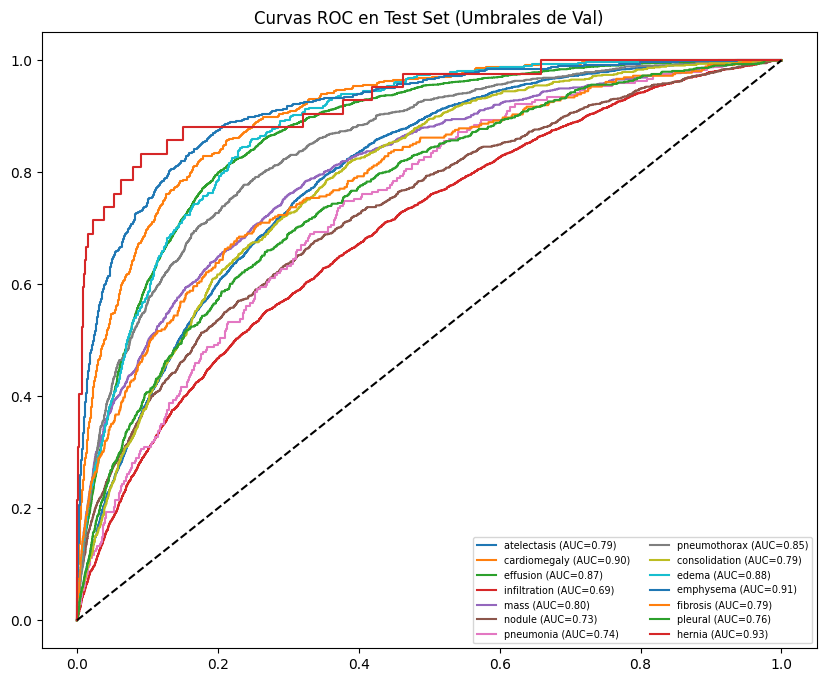

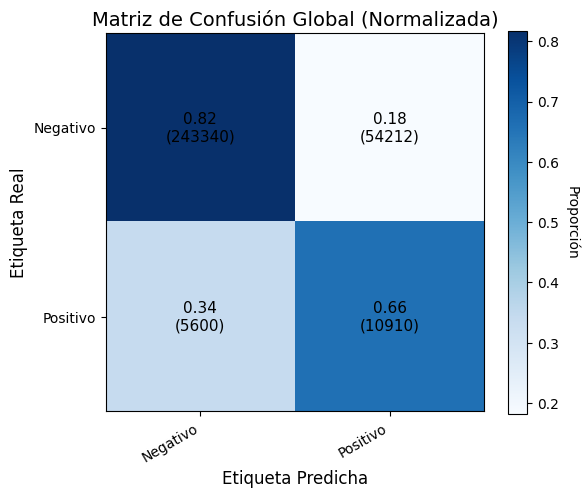

In [3]:
# Fase de calibración de umbrales usando el set de validación
# ===== VALIDATION: obtener scores =====
print("Cargando los mejores pesos del modelo guardados por Early Stopping...")
# VARIABLES NECESARIAS PARA LA CARGA
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_wl_224x224.pth')
DATA_FLAG = 'chestmnist'
info = INFO[DATA_FLAG]
n_classes = len(info['label'])
DOWNLOAD = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
data_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])
train_dataset = medmnist.ChestMNIST(split='train', transform=data_transform, download=DOWNLOAD, size=224)
train_labels = train_dataset.labels
# 2. Calcular el número de positivos y negativos por clase
num_positives = train_labels.sum(axis=0)
num_negatives = len(train_labels) - num_positives
# 3. Calcular el peso: Negativos / Positivos
# Sumamos un pequeño valor (1e-5) al denominador para evitar divisiones por cero
pos_weights_array = num_negatives / (num_positives + 1e-5)
# 4. Convertir a tensor de PyTorch y mandarlo a la GPU/CPU
pos_weights = torch.tensor(pos_weights_array, dtype=torch.float32).to(DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)
#######################################################################
print(f"Saved model detected. Loading weights from {MODEL_PATH}")
model = models.resnet50(weights=None)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, n_classes)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model = model.to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH))


val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model.to(DEVICE)
model.eval()

y_score_val = []
y_true_val = []

with torch.no_grad():
    for inputs, targets in tqdm(val_loader, desc="Calibrando Umbrales (Val Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = model(inputs)

        y_score_val.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_val.append(targets.cpu().numpy())

y_score_val = np.vstack(y_score_val)
y_true_val = np.vstack(y_true_val)

# ===== OPTIMIZACIÓN DE THRESHOLDS POR CLASE (F1) =====
num_classes = y_true_val.shape[1]
optimal_thresholds = np.zeros(num_classes)

best_f1 = 0
best_thresholds = None

for t in np.linspace(0.05, 0.5, 50):
    y_pred = (y_score_val >= t).astype(int)
    f1 = f1_score(y_true_val, y_pred, average='macro', zero_division=0)

    if f1 > best_f1:
        best_f1 = f1
        best_thresholds = np.full(num_classes, t)

optimal_thresholds = best_thresholds

# ===== PRINT =====
print("\n--- Umbrales Óptimos (optimizando F1 por clase) ---")
for i in range(num_classes):
    print(f"{info['label'][str(i)][:15]:<15} -> {optimal_thresholds[i]:.4f}")


# Fase de evaluación final en el set de test
# Cargar set de test
test_dataset = medmnist.ChestMNIST(split='test', transform=data_transform, download=DOWNLOAD, size=224)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

y_score_test = []
y_true_test = []
test_loss = 0

with torch.no_grad():
    for inputs, targets in tqdm(test_loader, desc="Evaluación Final (Test Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = model(inputs)
        test_loss += criterion(outputs, targets).item()
        y_score_test.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_test.append(targets.cpu().numpy())

y_score_test = np.vstack(y_score_test)
y_true_test = np.vstack(y_true_test)

# Aplicar los umbrales de VALIDATION al TEST
y_pred_test = (y_score_test >= optimal_thresholds).astype(int)

# --- Cálculo de Métricas ---
from sklearn.metrics import auc as metrics_auc

roc_aucs_test = [metrics_auc(roc_curve(y_true_test[:, i], y_score_test[:, i])[0], 
                             roc_curve(y_true_test[:, i], y_score_test[:, i])[1]) for i in range(num_classes)]

acc_global = accuracy_score(y_true_test, y_pred_test)
f1_macro = f1_score(y_true_test, y_pred_test, average='macro', zero_division=0)
f1_micro = f1_score(y_true_test, y_pred_test, average='micro', zero_division=0)
h_score = 1 - hamming_loss(y_true_test, y_pred_test)

# Balanced Accuracy Promedio
balanced_accs = [balanced_accuracy_score(y_true_test[:, i], y_pred_test[:, i]) for i in range(num_classes)]

# Imprimir Resultados Finales
print(f"\n{'='*40}")
print(f"   RESULTADOS FINALES EN TEST SET")
print(f"{'='*40}")
print(f"- AUC-ROC Macro Media  : {np.mean(roc_aucs_test):.4f}")
print(f"- Hamming Score (Acc)  : {h_score:.4f}")
print(f"- Mean Balanced Acc    : {np.mean(balanced_accs):.4f}")
print(f"- F1-Score Macro       : {f1_macro:.4f}")
print(f"- F1-Score Micro       : {f1_micro:.4f}")
print(f"- Accuracy Global (EMR): {acc_global:.4f}")
print(f"{'='*40}")

# Graficar las curvas ROC del TEST
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_test[:, i], y_score_test[:, i])
    plt.plot(fpr, tpr, label=f"{info['label'][str(i)]} (AUC={roc_aucs_test[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Curvas ROC en Test Set (Umbrales de Val)')
plt.legend(loc='lower right', ncol=2, fontsize='x-small')
plt.show()



# Matriz de confusión global
cm_global = confusion_matrix(y_true_test.flatten(), y_pred_test.flatten())

# Normalización (opcional, recomendado)
cm_norm = cm_global.astype('float') / cm_global.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
# Heatmap
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues')
# Título y etiquetas
ax.set_title("Matriz de Confusión Global (Normalizada)", fontsize=14)
ax.set_xlabel("Etiqueta Predicha", fontsize=12)
ax.set_ylabel("Etiqueta Real", fontsize=12)
# Ticks
classes = ['Negativo', 'Positivo']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)
# Rotar etiquetas eje X
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
# Añadir valores dentro
for i in range(2):
    for j in range(2):
        value = cm_norm[i, j]
        ax.text(j, i, f"{value:.2f}\n({cm_global[i, j]})",
                ha="center", va="center",
                color="black", fontsize=11)

# Barra de color
cbar = fig.colorbar(im, ax=ax)
cbar.ax.set_ylabel("Proporción", rotation=-90, va="bottom")
plt.tight_layout()
plt.show()

## Focal Loss

In [5]:
class FocalLossWithLogits(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, reduction='mean'):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        # Calculamos la BCE estándar por cada elemento
        bce_loss = F.binary_cross_entropy_with_logits(inputs, targets, reduction='none')
        
        # Calculamos pt (la probabilidad de que el modelo haya acertado)
        pt = torch.exp(-bce_loss) 
        
        # Fórmula del Focal Loss
        focal_loss = self.alpha * (1 - pt) ** self.gamma * bce_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss

In [5]:
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_fl_224x224.pth')

# Parameters
DATA_FLAG = 'chestmnist'
DOWNLOAD = True
BATCH_SIZE = 64
EPOCHS = 50
PATIENCE = 2
LEARNING_RATE = 1e-4
EARLY_STOPPING = EarlyStopping(patience=PATIENCE, verbose=True, path=MODEL_PATH)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

info = INFO[DATA_FLAG]
n_classes = len(info['label'])

# Data Transforms
data_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])

# Datasets and DataLoaders
train_dataset = medmnist.ChestMNIST(split='train', transform=data_transform, download=DOWNLOAD, size=224)
val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)

train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Torchvision ResNet-50 for multi-label task pretrained on ImageNet
if not os.path.exists(MODEL_DIR):
    os.makedirs(MODEL_DIR)
if os.path.exists(MODEL_PATH):
    print(f"Saved model detected. Loading weights from {MODEL_PATH}")
    model = models.resnet50(weights=None)
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, n_classes)
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
else:
    print("No saved model found. Starting with ImageNet weights.")
    model = models.resnet50(weights='IMAGENET1K_V1')
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, n_classes)
model = model.to(DEVICE)

# Focal Loss con logits para multi-label classification
criterion = FocalLossWithLogits(alpha=0.25, gamma=2.0)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
evaluator = Evaluator(DATA_FLAG, split='val')

# Training and validation loop with early stopping
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for inputs, targets in tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation phase
    model.eval()
    y_score = torch.tensor([]).to(DEVICE)
    val_loss = 0
    
    with torch.no_grad():
        for inputs, targets in tqdm(val_loader, desc=f"Epoch {epoch+1} [Val]"):
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
            outputs = model(inputs)
            
            val_loss += criterion(outputs, targets).item()
            
            # Probabilities for AUC
            m = nn.Sigmoid()
            y_score = torch.cat((y_score, m(outputs)), 0)

    # Calculate AUC and Accuracy
    auc, acc = evaluator.evaluate(y_score.cpu().numpy())
    
    print(f"Epoch {epoch+1}: Loss: {val_loss/len(val_loader):.4f} | AUC: {auc:.4f} | Acc: {acc:.4f}")

    # Early Stopping Check
    EARLY_STOPPING(auc, model)
    
    if EARLY_STOPPING.early_stop:
        print("\nEarly stopping activated. Terminating training.")
        break

Using device: cuda
No saved model found. Starting with ImageNet weights.


Epoch 1 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.18it/s]


Epoch 1: Loss: 0.0103 | AUC: 0.8166 | Acc: 0.9497
AUC improved (-inf -> 0.8166). Saving model.



Epoch 2 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.11it/s]


Epoch 2: Loss: 0.0103 | AUC: 0.8245 | Acc: 0.9497
AUC improved (0.8166 -> 0.8245). Saving model.



Epoch 3 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.17it/s]


Epoch 3: Loss: 0.0106 | AUC: 0.8198 | Acc: 0.9491
EarlyStopping counter: 1 out of 2



Epoch 4 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.15it/s]


Epoch 4: Loss: 0.0115 | AUC: 0.8116 | Acc: 0.9427
EarlyStopping counter: 2 out of 2


Early stopping activated. Terminating training.


Cargando los mejores pesos del modelo guardados por Early Stopping...
Saved model detected. Loading weights from models\best_resnet50_fl_224x224.pth


Calibrando Umbrales (Val Set): 100%|██████████| 176/176 [00:21<00:00,  8.11it/s]



--- Umbrales Óptimos (optimizando F1 por clase) ---
atelectasis     -> 0.3163
cardiomegaly    -> 0.3163
effusion        -> 0.3163
infiltration    -> 0.3163
mass            -> 0.3163
nodule          -> 0.3163
pneumonia       -> 0.3163
pneumothorax    -> 0.3163
consolidation   -> 0.3163
edema           -> 0.3163
emphysema       -> 0.3163
fibrosis        -> 0.3163
pleural         -> 0.3163
hernia          -> 0.3163


Evaluación Final (Test Set): 100%|██████████| 351/351 [00:43<00:00,  7.99it/s]



   RESULTADOS FINALES EN TEST SET
- AUC-ROC Macro Media  : 0.8231
- Hamming Score (Acc)  : 0.8860
- Mean Balanced Acc    : 0.6464
- F1-Score Macro       : 0.2840
- F1-Score Micro       : 0.3545
- Accuracy Global (EMR): 0.2236


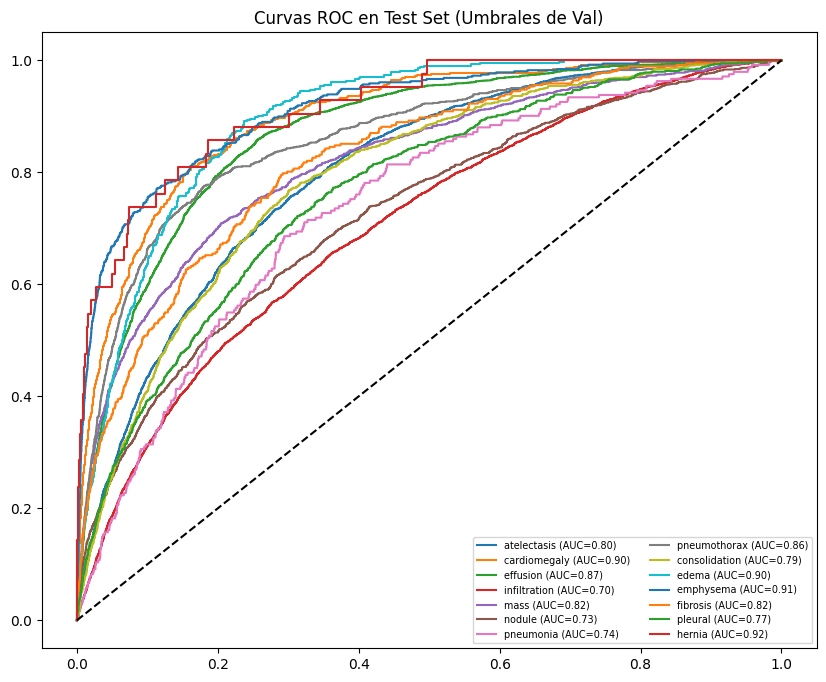

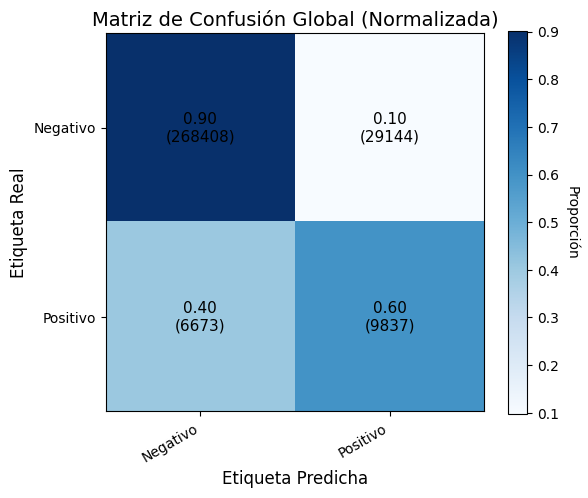

In [6]:
# Fase de calibración de umbrales usando el set de validación
# ===== VALIDATION: obtener scores =====
print("Cargando los mejores pesos del modelo guardados por Early Stopping...")
# VARIABLES NECESARIAS PARA LA CARGA
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_fl_224x224.pth')
DATA_FLAG = 'chestmnist'
info = INFO[DATA_FLAG]
n_classes = len(info['label'])
DOWNLOAD = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
criterion = FocalLossWithLogits(alpha=0.25, gamma=2.0)
#######################################################################
print(f"Saved model detected. Loading weights from {MODEL_PATH}")
model = models.resnet50(weights=None)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, n_classes)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model = model.to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH))

data_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])

val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model.to(DEVICE)
model.eval()

y_score_val = []
y_true_val = []

with torch.no_grad():
    for inputs, targets in tqdm(val_loader, desc="Calibrando Umbrales (Val Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = model(inputs)

        y_score_val.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_val.append(targets.cpu().numpy())

y_score_val = np.vstack(y_score_val)
y_true_val = np.vstack(y_true_val)

# ===== OPTIMIZACIÓN DE THRESHOLDS POR CLASE (F1) =====
num_classes = y_true_val.shape[1]
optimal_thresholds = np.zeros(num_classes)

best_f1 = 0
best_thresholds = None

for t in np.linspace(0.05, 0.5, 50):
    y_pred = (y_score_val >= t).astype(int)
    f1 = f1_score(y_true_val, y_pred, average='macro', zero_division=0)

    if f1 > best_f1:
        best_f1 = f1
        best_thresholds = np.full(num_classes, t)

optimal_thresholds = best_thresholds

# ===== PRINT =====
print("\n--- Umbrales Óptimos (optimizando F1 por clase) ---")
for i in range(num_classes):
    print(f"{info['label'][str(i)][:15]:<15} -> {optimal_thresholds[i]:.4f}")


# Fase de evaluación final en el set de test
# Cargar set de test
test_dataset = medmnist.ChestMNIST(split='test', transform=data_transform, download=DOWNLOAD, size=224)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

y_score_test = []
y_true_test = []
test_loss = 0

with torch.no_grad():
    for inputs, targets in tqdm(test_loader, desc="Evaluación Final (Test Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = model(inputs)
        test_loss += criterion(outputs, targets).item()
        y_score_test.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_test.append(targets.cpu().numpy())

y_score_test = np.vstack(y_score_test)
y_true_test = np.vstack(y_true_test)

# Aplicar los umbrales de VALIDATION al TEST
y_pred_test = (y_score_test >= optimal_thresholds).astype(int)

# --- Cálculo de Métricas ---
from sklearn.metrics import auc as metrics_auc

roc_aucs_test = [metrics_auc(roc_curve(y_true_test[:, i], y_score_test[:, i])[0], 
                             roc_curve(y_true_test[:, i], y_score_test[:, i])[1]) for i in range(num_classes)]

acc_global = accuracy_score(y_true_test, y_pred_test)
f1_macro = f1_score(y_true_test, y_pred_test, average='macro', zero_division=0)
f1_micro = f1_score(y_true_test, y_pred_test, average='micro', zero_division=0)
h_score = 1 - hamming_loss(y_true_test, y_pred_test)

# Balanced Accuracy Promedio
balanced_accs = [balanced_accuracy_score(y_true_test[:, i], y_pred_test[:, i]) for i in range(num_classes)]

# Imprimir Resultados Finales
print(f"\n{'='*40}")
print(f"   RESULTADOS FINALES EN TEST SET")
print(f"{'='*40}")
print(f"- AUC-ROC Macro Media  : {np.mean(roc_aucs_test):.4f}")
print(f"- Hamming Score (Acc)  : {h_score:.4f}")
print(f"- Mean Balanced Acc    : {np.mean(balanced_accs):.4f}")
print(f"- F1-Score Macro       : {f1_macro:.4f}")
print(f"- F1-Score Micro       : {f1_micro:.4f}")
print(f"- Accuracy Global (EMR): {acc_global:.4f}")
print(f"{'='*40}")

# Graficar las curvas ROC del TEST
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_test[:, i], y_score_test[:, i])
    plt.plot(fpr, tpr, label=f"{info['label'][str(i)]} (AUC={roc_aucs_test[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Curvas ROC en Test Set (Umbrales de Val)')
plt.legend(loc='lower right', ncol=2, fontsize='x-small')
plt.show()




# Matriz de confusión global
cm_global = confusion_matrix(y_true_test.flatten(), y_pred_test.flatten())

# Normalización (opcional, recomendado)
cm_norm = cm_global.astype('float') / cm_global.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
# Heatmap
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues')
# Título y etiquetas
ax.set_title("Matriz de Confusión Global (Normalizada)", fontsize=14)
ax.set_xlabel("Etiqueta Predicha", fontsize=12)
ax.set_ylabel("Etiqueta Real", fontsize=12)
# Ticks
classes = ['Negativo', 'Positivo']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)
# Rotar etiquetas eje X
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
# Añadir valores dentro
for i in range(2):
    for j in range(2):
        value = cm_norm[i, j]
        ax.text(j, i, f"{value:.2f}\n({cm_global[i, j]})",
                ha="center", va="center",
                color="black", fontsize=11)

# Barra de color
cbar = fig.colorbar(im, ax=ax)
cbar.ax.set_ylabel("Proporción", rotation=-90, va="bottom")
plt.tight_layout()
plt.show()

## Asymmetric Loss

In [7]:
class AsymmetricLoss(nn.Module):
    def __init__(self, gamma_neg=4, gamma_pos=1, clip=0.05, eps=1e-8):
        super(AsymmetricLoss, self).__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip = clip
        self.eps = eps

    def forward(self, x, y):
        # x son los logits (salida directa del modelo), aplicamos sigmoid
        xs_pos = torch.sigmoid(x)
        xs_neg = 1 - xs_pos

        # Asymmetric Clipping: los negativos muy fáciles (probabilidad < clip) se ignoran
        if self.clip is not None and self.clip > 0:
            xs_neg = (xs_neg + self.clip).clamp(max=1)

        # Cálculo base de Cross Entropy
        los_pos = y * torch.log(xs_pos.clamp(min=self.eps))
        los_neg = (1 - y) * torch.log(xs_neg.clamp(min=self.eps))
        loss = los_pos + los_neg

        # Asymmetric Focusing
        pt0 = xs_pos * y
        pt1 = xs_neg * (1 - y)  # pt = p si y > 0 sino 1-p
        pt = pt0 + pt1
        
        one_sided_gamma = self.gamma_pos * y + self.gamma_neg * (1 - y)
        one_sided_w = torch.pow(1 - pt, one_sided_gamma)

        loss *= one_sided_w
        return -loss.mean()

In [8]:
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_al_224x224.pth')

# Parameters
DATA_FLAG = 'chestmnist'
DOWNLOAD = True
BATCH_SIZE = 64
EPOCHS = 50
PATIENCE = 2
LEARNING_RATE = 1e-4
EARLY_STOPPING = EarlyStopping(patience=PATIENCE, verbose=True, path=MODEL_PATH)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

info = INFO[DATA_FLAG]
n_classes = len(info['label'])

# Data Transforms
data_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])

# Datasets and DataLoaders
train_dataset = medmnist.ChestMNIST(split='train', transform=data_transform, download=DOWNLOAD, size=224)
val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)

train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Torchvision ResNet-50 for multi-label task pretrained on ImageNet
if not os.path.exists(MODEL_DIR):
    os.makedirs(MODEL_DIR)
if os.path.exists(MODEL_PATH):
    print(f"Saved model detected. Loading weights from {MODEL_PATH}")
    model = models.resnet50(weights=None)
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, n_classes)
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
else:
    print("No saved model found. Starting with ImageNet weights.")
    model = models.resnet50(weights='IMAGENET1K_V1')
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, n_classes)
model = model.to(DEVICE)

# Focal Loss con logits para multi-label classification
criterion = AsymmetricLoss(gamma_neg=4, gamma_pos=1, clip=0.05)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
evaluator = Evaluator(DATA_FLAG, split='val')

# Training and validation loop with early stopping
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for inputs, targets in tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation phase
    model.eval()
    y_score = torch.tensor([]).to(DEVICE)
    val_loss = 0
    
    with torch.no_grad():
        for inputs, targets in tqdm(val_loader, desc=f"Epoch {epoch+1} [Val]"):
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
            outputs = model(inputs)
            
            val_loss += criterion(outputs, targets).item()
            
            # Probabilities for AUC
            m = nn.Sigmoid()
            y_score = torch.cat((y_score, m(outputs)), 0)

    # Calculate AUC and Accuracy
    auc, acc = evaluator.evaluate(y_score.cpu().numpy())
    
    print(f"Epoch {epoch+1}: Loss: {val_loss/len(val_loader):.4f} | AUC: {auc:.4f} | Acc: {acc:.4f}")

    # Early Stopping Check
    EARLY_STOPPING(auc, model)
    
    if EARLY_STOPPING.early_stop:
        print("\nEarly stopping activated. Terminating training.")
        break

Using device: cuda
No saved model found. Starting with ImageNet weights.


Epoch 1 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.15it/s]


Epoch 1: Loss: 0.0263 | AUC: 0.8084 | Acc: 0.8948
AUC improved (-inf -> 0.8084). Saving model.



Epoch 2 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.18it/s]


Epoch 2: Loss: 0.0262 | AUC: 0.8188 | Acc: 0.9060
AUC improved (0.8084 -> 0.8188). Saving model.



Epoch 3 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.19it/s]


Epoch 3: Loss: 0.0264 | AUC: 0.8145 | Acc: 0.8917
EarlyStopping counter: 1 out of 2



Epoch 4 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.22it/s]


Epoch 4: Loss: 0.0283 | AUC: 0.8111 | Acc: 0.8956
EarlyStopping counter: 2 out of 2


Early stopping activated. Terminating training.


Cargando los mejores pesos del modelo guardados por Early Stopping...
Saved model detected. Loading weights from models\best_resnet50_al_224x224.pth


Calibrando Umbrales (Val Set): 100%|██████████| 176/176 [00:21<00:00,  8.08it/s]



--- Umbrales Óptimos (optimizando F1 por clase) ---
atelectasis     -> 0.4541
cardiomegaly    -> 0.4541
effusion        -> 0.4541
infiltration    -> 0.4541
mass            -> 0.4541
nodule          -> 0.4541
pneumonia       -> 0.4541
pneumothorax    -> 0.4541
consolidation   -> 0.4541
edema           -> 0.4541
emphysema       -> 0.4541
fibrosis        -> 0.4541
pleural         -> 0.4541
hernia          -> 0.4541


Evaluación Final (Test Set): 100%|██████████| 351/351 [00:45<00:00,  7.65it/s]



   RESULTADOS FINALES EN TEST SET
- AUC-ROC Macro Media  : 0.8259
- Hamming Score (Acc)  : 0.8545
- Mean Balanced Acc    : 0.6546
- F1-Score Macro       : 0.2536
- F1-Score Micro       : 0.3265
- Accuracy Global (EMR): 0.1761


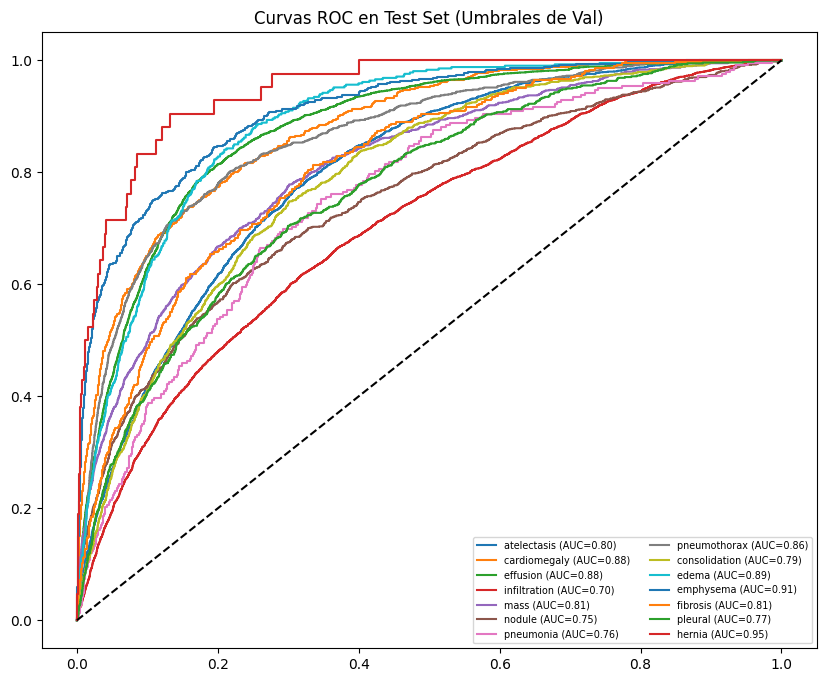

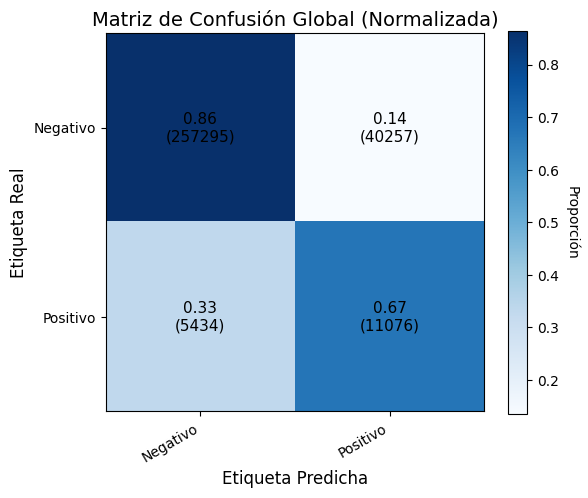

In [8]:
# Fase de calibración de umbrales usando el set de validación
# ===== VALIDATION: obtener scores =====
print("Cargando los mejores pesos del modelo guardados por Early Stopping...")
# VARIABLES NECESARIAS PARA LA CARGA
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_al_224x224.pth')
DATA_FLAG = 'chestmnist'
info = INFO[DATA_FLAG]
n_classes = len(info['label'])
DOWNLOAD = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
criterion = AsymmetricLoss(gamma_neg=4, gamma_pos=1, clip=0.05)
#######################################################################
print(f"Saved model detected. Loading weights from {MODEL_PATH}")
model = models.resnet50(weights=None)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, n_classes)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model = model.to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH))

data_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])

val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model.to(DEVICE)
model.eval()

y_score_val = []
y_true_val = []

with torch.no_grad():
    for inputs, targets in tqdm(val_loader, desc="Calibrando Umbrales (Val Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = model(inputs)

        y_score_val.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_val.append(targets.cpu().numpy())

y_score_val = np.vstack(y_score_val)
y_true_val = np.vstack(y_true_val)

# ===== OPTIMIZACIÓN DE THRESHOLDS POR CLASE (F1) =====
num_classes = y_true_val.shape[1]
optimal_thresholds = np.zeros(num_classes)

best_f1 = 0
best_thresholds = None

for t in np.linspace(0.05, 0.5, 50):
    y_pred = (y_score_val >= t).astype(int)
    f1 = f1_score(y_true_val, y_pred, average='macro', zero_division=0)

    if f1 > best_f1:
        best_f1 = f1
        best_thresholds = np.full(num_classes, t)

optimal_thresholds = best_thresholds

# ===== PRINT =====
print("\n--- Umbrales Óptimos (optimizando F1 por clase) ---")
for i in range(num_classes):
    print(f"{info['label'][str(i)][:15]:<15} -> {optimal_thresholds[i]:.4f}")


# Fase de evaluación final en el set de test
# Cargar set de test
test_dataset = medmnist.ChestMNIST(split='test', transform=data_transform, download=DOWNLOAD, size=224)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

y_score_test = []
y_true_test = []
test_loss = 0

with torch.no_grad():
    for inputs, targets in tqdm(test_loader, desc="Evaluación Final (Test Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = model(inputs)
        test_loss += criterion(outputs, targets).item()
        y_score_test.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_test.append(targets.cpu().numpy())

y_score_test = np.vstack(y_score_test)
y_true_test = np.vstack(y_true_test)

# Aplicar los umbrales de VALIDATION al TEST
y_pred_test = (y_score_test >= optimal_thresholds).astype(int)

# --- Cálculo de Métricas ---
from sklearn.metrics import auc as metrics_auc

roc_aucs_test = [metrics_auc(roc_curve(y_true_test[:, i], y_score_test[:, i])[0], 
                             roc_curve(y_true_test[:, i], y_score_test[:, i])[1]) for i in range(num_classes)]

acc_global = accuracy_score(y_true_test, y_pred_test)
f1_macro = f1_score(y_true_test, y_pred_test, average='macro', zero_division=0)
f1_micro = f1_score(y_true_test, y_pred_test, average='micro', zero_division=0)
h_score = 1 - hamming_loss(y_true_test, y_pred_test)

# Balanced Accuracy Promedio
balanced_accs = [balanced_accuracy_score(y_true_test[:, i], y_pred_test[:, i]) for i in range(num_classes)]

# Imprimir Resultados Finales
print(f"\n{'='*40}")
print(f"   RESULTADOS FINALES EN TEST SET")
print(f"{'='*40}")
print(f"- AUC-ROC Macro Media  : {np.mean(roc_aucs_test):.4f}")
print(f"- Hamming Score (Acc)  : {h_score:.4f}")
print(f"- Mean Balanced Acc    : {np.mean(balanced_accs):.4f}")
print(f"- F1-Score Macro       : {f1_macro:.4f}")
print(f"- F1-Score Micro       : {f1_micro:.4f}")
print(f"- Accuracy Global (EMR): {acc_global:.4f}")
print(f"{'='*40}")

# Graficar las curvas ROC del TEST
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_test[:, i], y_score_test[:, i])
    plt.plot(fpr, tpr, label=f"{info['label'][str(i)]} (AUC={roc_aucs_test[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Curvas ROC en Test Set (Umbrales de Val)')
plt.legend(loc='lower right', ncol=2, fontsize='x-small')
plt.show()




# Matriz de confusión global
cm_global = confusion_matrix(y_true_test.flatten(), y_pred_test.flatten())

# Normalización (opcional, recomendado)
cm_norm = cm_global.astype('float') / cm_global.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
# Heatmap
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues')
# Título y etiquetas
ax.set_title("Matriz de Confusión Global (Normalizada)", fontsize=14)
ax.set_xlabel("Etiqueta Predicha", fontsize=12)
ax.set_ylabel("Etiqueta Real", fontsize=12)
# Ticks
classes = ['Negativo', 'Positivo']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)
# Rotar etiquetas eje X
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
# Añadir valores dentro
for i in range(2):
    for j in range(2):
        value = cm_norm[i, j]
        ax.text(j, i, f"{value:.2f}\n({cm_global[i, j]})",
                ha="center", va="center",
                color="black", fontsize=11)

# Barra de color
cbar = fig.colorbar(im, ax=ax)
cbar.ax.set_ylabel("Proporción", rotation=-90, va="bottom")
plt.tight_layout()
plt.show()